In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT / 'data').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from utils.calculations import calculate_scenarios, add_npv_columns, best_scenario, monthly_discount_rate, format_rub, format_mln
CONFIG = json.loads((ROOT / 'data' / 'task_04_ad_load_config.json').read_text(encoding='utf-8'))
base = add_npv_columns(CONFIG, calculate_scenarios(CONFIG))
monthly_rate_text = f"{monthly_discount_rate(CONFIG)*100:.3f}".replace('.', ',')
task_opening = f"""# Экзаменационная задача №{CONFIG['task_id']}: {CONFIG['title']}

**Студент:** {CONFIG['student_name']}  
**Группа:** {CONFIG['group']}  
**Платформа:** {CONFIG['platform']}  
**Горизонт анализа:** {CONFIG['analysis_horizon_months']} месяцев  
**Эффективная месячная ставка дисконтирования:** {monthly_rate_text}%

Все исходные данные загружаются из JSON, а таблицы, графики и выводы рассчитываются ниже по формулам модели."""
display(Markdown(task_opening))


# Экзаменационная задача №4: Оптимизация рекламной нагрузки для платформы видеоконтента

**Студент:** Глазков Тимофей Владимирович  
**Группа:** БИ ОЗФО5-1  
**Платформа:** ВидеоСервис  
**Горизонт анализа:** 36 месяцев  
**Эффективная месячная ставка дисконтирования:** 0,949%

Все исходные данные загружаются из JSON, а таблицы, графики и выводы рассчитываются ниже по формулам модели.

## Условие задачи

Платформа «ВидеоСервис» зарабатывает на рекламе и подписке. Необходимо найти оптимальную рекламную нагрузку, максимизирующую общую прибыль.

**Исходные данные:**

- число активных пользователей — 5 млн;
- доход от подписки — 300 руб./пользователь в месяц;
- доход от рекламы — 20 руб. за 1 000 показов (CPM = 20 руб.);
- среднее число видео в день на пользователя — 10;
- CAC — 2 000 руб./пользователь;
- средний срок жизни пользователя — 24 месяца;
- ставка дисконтирования — 12% годовых.

**Влияние рекламной нагрузки:**

Для уровней нагрузки 0, 10, 20, 30, 40, 50 и 60 показов в день заданы соответствующие значения оттока пользователей и времени просмотра. Требуется рассчитать доход от рекламы, доход от подписки, потери от оттока, общую прибыль, оптимальный уровень нагрузки, чувствительность результата и управленческие рекомендации.

## Экономическая постановка

Платформа получает доход от рекламы и подписки. Рост рекламной нагрузки увеличивает рекламную выручку, но может ухудшать пользовательский опыт и повышать отток. Требуется выбрать уровень нагрузки с максимальным экономическим результатом, проверить устойчивость решения и определить показатели для мониторинга.

## Исходные данные

В расчётах разделены:

1. **Денежный поток** — текущая выручка за месяц минус фактическая стоимость замещения ушедших пользователей. Именно этот показатель используется для основного NPV.
2. **Упущенный LTV** — оценка будущей подписной выручки, которую можно потерять из-за оттока. Она показывается отдельно и используется для консервативного экономического сценария, но не смешивается с основным cash flow.

In [2]:
input_data = pd.DataFrame({
    'Показатель': ['Платформа','Активные пользователи','ARPU подписки','CPM','Дней в месяце','Видео на пользователя в день','CAC','Средний срок жизни','Горизонт анализа','Годовая ставка дисконтирования','Первоначальные инвестиции'],
    'Значение': [CONFIG['platform'], format_rub(CONFIG['active_users'])+' чел.', format_rub(CONFIG['subscription_arpu_rub_month'])+' руб./мес.', format_rub(CONFIG['cpm_rub'])+' руб./1000 показов', str(CONFIG['days_per_month']), str(CONFIG['videos_per_user_day']), format_rub(CONFIG['cac_rub'])+' руб.', str(CONFIG['lifetime_months'])+' мес.', str(CONFIG['analysis_horizon_months'])+' мес.', f"{CONFIG['discount_rate_annual']*100:.1f}".replace('.', ',')+'% годовых', format_rub(CONFIG['initial_investment_rub'])+' руб.']
})
display(input_data)
influence = pd.DataFrame({'Нагрузка, показов/день':CONFIG['load_levels_impressions_day'],'Отток, %':[f"{x*100:.1f}".replace('.',',')+'%' for x in CONFIG['churn_rates']],'Время просмотра, мин':CONFIG['watch_time_minutes']})
display(influence)

,Показатель,Значение
0,Платформа,ВидеоСервис
1,Активные пользователи,5 000 000 чел.
2,ARPU подписки,300 руб./мес.
3,CPM,20 руб./1000 показов
4,Дней в месяце,30
5,Видео на пользователя в день,10
6,CAC,2 000 руб.
7,Средний срок жизни,24 мес.
8,Горизонт анализа,36 мес.
9,Годовая ставка дисконтирования,"12,0% годовых"


,"Нагрузка, показов/день","Отток, %","Время просмотра, мин"
0,0,"0,0%",120
1,10,"0,0%",115
2,20,"2,0%",110
3,30,"5,0%",100
4,40,"10,0%",90
5,50,"18,0%",75
6,60,"30,0%",60


## Часть 1. Расчёт денежных потоков

Сначала считаем, сколько денег платформа получает и теряет при каждом уровне рекламной нагрузки. Это нужно, чтобы сравнить сценарии между собой, а не выбирать нагрузку только по рекламной выручке.

Рекламная выручка: `Users × Load × Days × CPM / 1000`.

Подписная выручка: `Users × (1 − Churn) × ARPU`.

Фактический денежный поток: `Реклама + Подписка − Churned users × CAC`.

Упущенный LTV показывается отдельно: `Churned users × ARPU × Lifetime`. Это не текущий платёж, поэтому он не прибавляется второй раз к основному cash flow.

### Как читать этот расчёт

1. **Рекламный доход** показывает, сколько платформа получает от показов. Чем больше показов и выше CPM, тем больше эта сумма.
2. **Доход от подписки** показывает деньги от пользователей, которые остались после оттока.
3. **Потери CAC** показывают стоимость привлечения замены для ушедших пользователей.
4. **Упущенный LTV** показывает будущую подписную выручку, которая может быть потеряна из-за ухода пользователя. Это оценка риска, а не текущий платёж.
5. **Денежный поток** — показатель текущего месяца: рекламный доход плюс подписка минус фактические расходы на замещение ушедших пользователей.

In [3]:
table = base[['Нагрузка, показов/день','Отток, %','Время просмотра, мин','Доход рекламы, руб.','Доход подписки, руб.','Потери CAC, руб.','Упущенный LTV, руб.','Денежный поток, руб.']].copy()
for c in ['Доход рекламы, руб.','Доход подписки, руб.','Потери CAC, руб.','Упущенный LTV, руб.','Денежный поток, руб.']: table[c]=table[c].map(lambda x: format_mln(x))
table['Отток, %']=table['Отток, %'].map(lambda x:f"{x:.1f}".replace('.',',')+'%')
display(table)

,"Нагрузка, показов/день","Отток, %","Время просмотра, мин","Доход рекламы, руб.","Доход подписки, руб.","Потери CAC, руб.","Упущенный LTV, руб.","Денежный поток, руб."
0,0,"0,0%",120.0,"0,0","1 500,0","0,0","0,0","1 500,0"
1,10,"0,0%",115.0,"30,0","1 500,0","0,0","0,0","1 530,0"
2,20,"2,0%",110.0,"60,0","1 470,0","200,0","720,0","1 330,0"
3,30,"5,0%",100.0,"90,0","1 425,0","500,0","1 800,0","1 015,0"
4,40,"10,0%",90.0,"120,0","1 350,0","1 000,0","3 600,0","470,0"
5,50,"18,0%",75.0,"150,0","1 230,0","1 800,0","6 480,0","-420,0"
6,60,"30,0%",60.0,"180,0","1 050,0","3 000,0","10 800,0","-1 770,0"


### Графики для сравнения сценариев

Первый график показывает, как дополнительная реклама конкурирует с потерями от оттока. Второй показывает структуру месячного результата. По графикам видно, почему максимальная рекламная нагрузка не является автоматически лучшей.

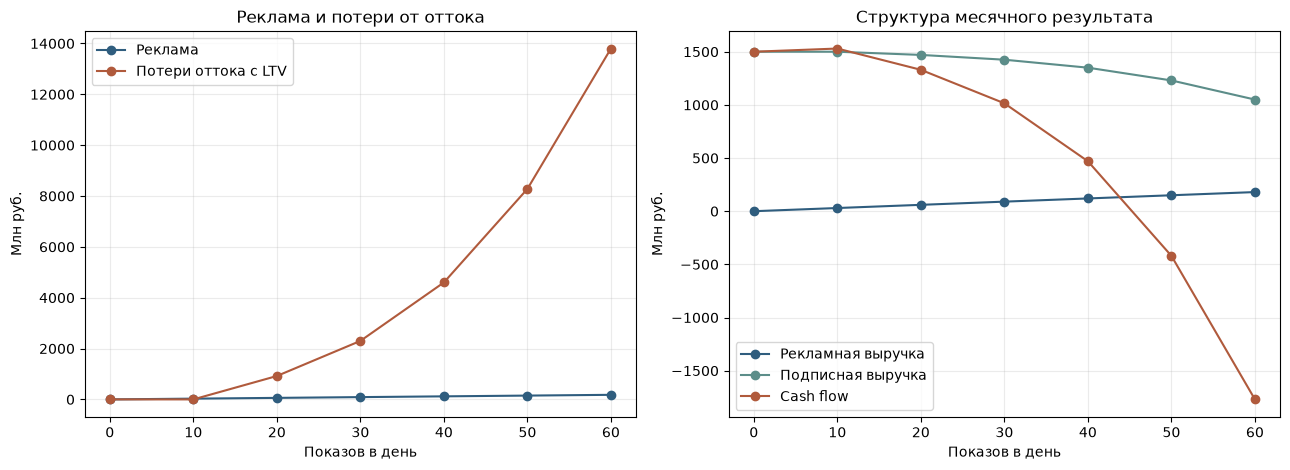

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(base['Нагрузка, показов/день'], base['Доход рекламы, руб.']/1e6, marker='o', label='Реклама', color='#2F5D7E')
axes[0].plot(base['Нагрузка, показов/день'], base['Потери оттока с LTV, руб.']/1e6, marker='o', label='Потери оттока с LTV', color='#B05A3C')
axes[0].set_title('Реклама и потери от оттока'); axes[0].set_xlabel('Показов в день'); axes[0].set_ylabel('Млн руб.'); axes[0].grid(alpha=.25); axes[0].legend()
axes[1].plot(base['Нагрузка, показов/день'], base['Доход рекламы, руб.']/1e6, marker='o', label='Рекламная выручка', color='#2F5D7E')
axes[1].plot(base['Нагрузка, показов/день'], base['Доход подписки, руб.']/1e6, marker='o', label='Подписная выручка', color='#5C8D89')
axes[1].plot(base['Нагрузка, показов/день'], base['Денежный поток, руб.']/1e6, marker='o', label='Cash flow', color='#B05A3C')
axes[1].set_title('Структура месячного результата'); axes[1].set_xlabel('Показов в день'); axes[1].set_ylabel('Млн руб.'); axes[1].grid(alpha=.25); axes[1].legend()
fig.tight_layout(); fig.savefig(ROOT/'reports'/'figures'/'task_04_revenue_and_losses.png', dpi=180, bbox_inches='tight'); plt.show()

## Часть 2. NPV и выбор оптимальной нагрузки

Теперь переводим месячные денежные потоки в стоимость проекта на текущий момент. Это нужно потому, что рубль, полученный сегодня, ценнее рубля, полученного через несколько месяцев.

Месячная ставка дисконтирования переводится из годовой эффективной ставки: `r_month = (1 + r_year)^(1/12) − 1`.

`NPV = −Initial investment + Σ(CF_t / (1 + r_month)^t)`.

Для выбора нагрузки используется NPV фактического денежного потока. Консервативный NPV с учётом LTV приводится отдельно.

### Как читать NPV

NPV отвечает на вопрос: **сколько стоит весь проект сегодня**, если каждый будущий денежный поток уменьшить на фактор времени и риска.

- NPV больше нуля — проект создаёт стоимость при заданных вводных.
- NPV меньше нуля — будущих дисконтированных поступлений недостаточно.
- Максимальный NPV среди сценариев — основание для выбора рекламной нагрузки.

In [5]:
npv_table=base[['Нагрузка, показов/день','Денежный поток, руб.','Экономический результат с LTV, руб.','NPV денежного потока, руб.','NPV с учётом LTV, руб.']].copy()
for c in npv_table.columns[1:]: npv_table[c]=npv_table[c].map(format_mln)
display(npv_table.rename(columns={'Денежный поток, руб.':'Месячный cash flow, млн руб.','Экономический результат с LTV, руб.':'Результат с LTV, млн руб.','NPV денежного потока, руб.':'NPV cash flow, млн руб.','NPV с учётом LTV, руб.':'Консервативный NPV с LTV, млн руб.'}))
best=best_scenario(base)
print(f"Оптимум по NPV cash flow: {int(best['Нагрузка, показов/день'])} показов/день; NPV = {format_mln(best['NPV денежного потока, руб.'])} млн руб.")
print(f"Консервативный NPV при этом же сценарии: {format_mln(best['NPV с учётом LTV, руб.'])} млн руб.")

,"Нагрузка, показов/день","Месячный cash flow, млн руб.","Результат с LTV, млн руб.","NPV cash flow, млн руб.","Консервативный NPV с LTV, млн руб."
0,0,"1 500,0","1 500,0","45 562,1","45 562,1"
1,10,"1 530,0","1 530,0","46 473,4","46 473,4"
2,20,"1 330,0","610,0","40 398,4","18 528,6"
3,30,"1 015,0","-785,0","30 830,4","-23 844,2"
4,40,"470,0","-3 130,0","14 276,1","-95 073,0"
5,50,"-420,0","-6 900,0","-12 757,4","-209 585,8"
6,60,"-1 770,0","-12 570,0","-53 763,3","-381 810,7"


Оптимум по NPV cash flow: 10 показов/день; NPV = 46 473,4 млн руб.
Консервативный NPV при этом же сценарии: 46 473,4 млн руб.


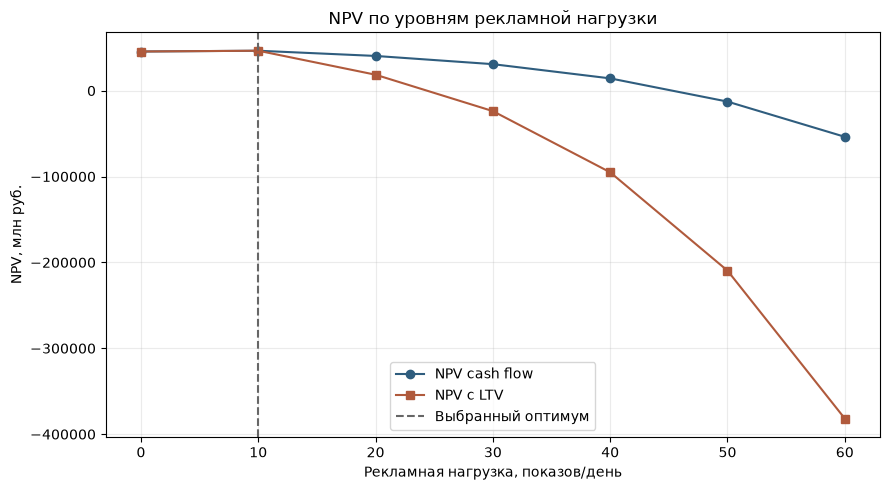

In [6]:
fig,ax=plt.subplots(figsize=(9,5))
ax.plot(base['Нагрузка, показов/день'],base['NPV денежного потока, руб.']/1e6,marker='o',label='NPV cash flow',color='#2F5D7E')
ax.plot(base['Нагрузка, показов/день'],base['NPV с учётом LTV, руб.']/1e6,marker='s',label='NPV с LTV',color='#B05A3C')
ax.axvline(best['Нагрузка, показов/день'],color='#666',linestyle='--',label='Выбранный оптимум')
ax.set_xlabel('Рекламная нагрузка, показов/день'); ax.set_ylabel('NPV, млн руб.'); ax.set_title('NPV по уровням рекламной нагрузки'); ax.grid(alpha=.25); ax.legend(); fig.tight_layout()
(ROOT/'reports'/'figures').mkdir(parents=True,exist_ok=True); fig.savefig(ROOT/'reports'/'figures'/'task_04_npv_by_load.png',dpi=180,bbox_inches='tight'); plt.show()

## Часть 3. Чувствительность

Проверяем, изменится ли рекомендация, если CPM или отток окажутся не такими, как в базовом сценарии.

Проверяется влияние CPM и изменения оттока. Все сценарные коэффициенты загружаются из JSON.

In [7]:
rows=[]
for cpm in CONFIG['sensitivity_cpm_rub']:
    s=add_npv_columns(CONFIG,calculate_scenarios(CONFIG,cpm=cpm)); b=best_scenario(s)
    rows.append({'CPM, руб.':cpm,'Оптимальная нагрузка':int(b['Нагрузка, показов/день']),'NPV, млн руб.':b['NPV денежного потока, руб.']/1e6})
cpm_sens=pd.DataFrame(rows); cpm_sens['NPV, млн руб.']=cpm_sens['NPV, млн руб.'].map(lambda x:format_rub(x,1)); display(cpm_sens)

,"CPM, руб.",Оптимальная нагрузка,"NPV, млн руб."
0,10,10,"46 017,8"
1,20,10,"46 473,4"
2,30,10,"46 929,0"


In [8]:
delta=CONFIG['churn_sensitivity_delta']; scenarios=[(f'−{delta:.0%}',1-delta),('База',1.0),(f'+{delta:.0%}',1+delta)]
rows=[]
for label,mult in scenarios:
    s=add_npv_columns(CONFIG,calculate_scenarios(CONFIG,churn_multiplier=mult)); b=best_scenario(s)
    rows.append({'Сценарий оттока':label,'Оптимальная нагрузка':int(b['Нагрузка, показов/день']),'Максимальный NPV, млн руб.':b['NPV денежного потока, руб.']/1e6})
churn_sens=pd.DataFrame(rows); churn_sens['Максимальный NPV, млн руб.']=churn_sens['Максимальный NPV, млн руб.'].map(lambda x:format_rub(x,1)); display(churn_sens)

,Сценарий оттока,Оптимальная нагрузка,"Максимальный NPV, млн руб."
0,−20%,10,"46 473,4"
1,База,10,"46 473,4"
2,+20%,10,"46 473,4"


## Часть 4. Сегментированная рекомендация и мониторинг

Одинаковая рекламная нагрузка не обязательно подходит всем пользователям. Поэтому отдельно формируем правила для платных, бесплатных, новых и неактивных пользователей.

In [9]:
policy=CONFIG['segment_policy']; opt=int(best['Нагрузка, показов/день']); free_max=opt+int(policy['free_test_range_increment']); paid_max=round(opt*policy['paid_max_fraction_of_optimal_load'])
segment=pd.DataFrame({'Сегмент':['Платные пользователи','Бесплатные пользователи','Новые пользователи','Неактивные пользователи'],'Рекомендация':[f"{policy['inactive_load']}–{paid_max}",f'{opt}–{free_max}',f"{policy['new_users_min_load']}–{policy['new_users_max_load']}",str(policy['inactive_load'])],'Логика':['Уже есть подписная выручка; приоритет удержание','Тестировать около рассчитанного оптимума','Осторожное знакомство с рекламой','Нет активного инвентаря']}); display(segment)
monitor=pd.DataFrame({'Метрика':['Churn Rate','ARPU','CTR','Время просмотра','NPS'],'Цель':[f"< {CONFIG['monitoring']['churn_limit_fraction']*100:.1f}%",f">= {format_rub(CONFIG['subscription_arpu_rub_month']*CONFIG['monitoring']['arpu_target_fraction_of_base'])} руб.",f">= {CONFIG['monitoring']['ctr_target']*100:.1f}%",f">= {CONFIG['watch_time_minutes'][0]*CONFIG['monitoring']['watch_time_min_fraction_of_baseline']:.0f} мин",f">= {CONFIG['monitoring']['nps_target']}"],'Действие при отклонении':['Снизить нагрузку и проверить отток','Проверить конверсию в подписку','Оптимизировать таргетинг','Снизить рекламную частоту','Провести анализ причин недовольства']}); display(monitor)

,Сегмент,Рекомендация,Логика
0,Платные пользователи,0–5,Уже есть подписная выручка; приоритет удержание
1,Бесплатные пользователи,10–20,Тестировать около рассчитанного оптимума
2,Новые пользователи,5–10,Осторожное знакомство с рекламой
3,Неактивные пользователи,0,Нет активного инвентаря


,Метрика,Цель,Действие при отклонении
0,Churn Rate,< 2.0%,Снизить нагрузку и проверить отток
1,ARPU,>= 300 руб.,Проверить конверсию в подписку
2,CTR,>= 2.0%,Оптимизировать таргетинг
3,Время просмотра,>= 108 мин,Снизить рекламную частоту
4,NPS,>= 50,Провести анализ причин недовольства


## Итоговый расчётный вывод

В модели NPV рассчитан по фактическому денежному потоку, а упущенный LTV вынесен в отдельный консервативный показатель. Это позволяет не выдавать будущую потерю дохода за текущий денежный расход и одновременно видеть долгосрочный риск оттока.

In [10]:
npv=float(best['NPV денежного потока, руб.']); status='положительный' if npv>=0 else 'отрицательный'; ltv_npv=float(best['NPV с учётом LTV, руб.'])
print(f"Оптимум: {int(best['Нагрузка, показов/день'])} показов в день.")
print(f"Месячный cash flow: {format_mln(best['Денежный поток, руб.'])} млн руб.; NPV: {format_mln(npv)} млн руб. ({status}).")
print(f"Консервативный NPV с учётом LTV: {format_mln(ltv_npv)} млн руб.")
print(f"Рекомендация: применять нагрузку около {opt} показов в день для бесплатного сегмента, а для платного ограничить её диапазоном 0–{paid_max}.")

Оптимум: 10 показов в день.
Месячный cash flow: 1 530,0 млн руб.; NPV: 46 473,4 млн руб. (положительный).
Консервативный NPV с учётом LTV: 46 473,4 млн руб.
Рекомендация: применять нагрузку около 10 показов в день для бесплатного сегмента, а для платного ограничить её диапазоном 0–5.


## Ограничения модели

Время просмотра и число видео в день используются как операционные показатели качества и контроля, поскольку в исходных данных нет денежной оценки минуты просмотра или CTR. Для реального проекта следующий шаг — связать время просмотра, конверсию, CTR и ARPU с наблюдаемыми когортными данными.

## Расширенный сценарий при наличии когортных данных

Если у платформы есть наблюдаемые данные по когортам, агрегированный ARPU можно дополнить или заменить более детальной моделью. В JSON для каждой рекламной нагрузки задаются: время просмотра, CTR, конверсия в платную подписку и ARPU платного пользователя. Ниже рассчитываются клики, число платных пользователей, когортная подписная выручка, месячный cash flow и NPV. Значения в конфигурации являются редактируемым примером и должны быть заменены фактическими данными продукта.

In [11]:
from utils.calculations import calculate_cohort_scenarios
cohort_cfg=CONFIG['cohort_model']
if cohort_cfg['enabled']:
    cohort=calculate_cohort_scenarios(CONFIG)
    cohort_table=cohort[['Нагрузка, показов/день','Время просмотра, мин','CTR, %','Конверсия в подписку, %','Платные пользователи','Клики','Когортная подписная выручка, руб.','Денежный поток, руб.','NPV денежного потока, руб.']].copy()
    cohort_table['CTR, %']=cohort_table['CTR, %'].map(lambda x:f'{x:.2f}'.replace('.',',')+'%')
    cohort_table['Конверсия в подписку, %']=cohort_table['Конверсия в подписку, %'].map(lambda x:f'{x:.2f}'.replace('.',',')+'%')
    cohort_table['Платные пользователи']=cohort_table['Платные пользователи'].map(lambda x:format_rub(x,0))
    cohort_table['Клики']=cohort_table['Клики'].map(lambda x:format_rub(x,0))
    for col in ['Когортная подписная выручка, руб.','Денежный поток, руб.','NPV денежного потока, руб.']:
        cohort_table[col]=cohort_table[col].map(format_mln)
    display(cohort_table.rename(columns={'Когортная подписная выручка, руб.':'Подписная выручка, млн руб.','Денежный поток, руб.':'Cash flow, млн руб.','NPV денежного потока, руб.':'NPV, млн руб.'}))
    cohort_best=cohort.loc[cohort['NPV денежного потока, руб.'].idxmax()]
    print(f"Когортная модель: оптимум = {int(cohort_best['Нагрузка, показов/день'])} показов/день; NPV = {format_mln(cohort_best['NPV денежного потока, руб.'])} млн руб.")
    print(f"Источник параметров: {cohort_cfg['data_source_note']}")
else:
    print('Когортная модель отключена в JSON: cohort_model.enabled = false.')

,"Нагрузка, показов/день","Время просмотра, мин","CTR, %","Конверсия в подписку, %",Платные пользователи,Клики,"Подписная выручка, млн руб.","Cash flow, млн руб.","NPV, млн руб."
0,0,120.0,"1,00%","30,00%",1 500 000,0,"450,0","450,0","13 668,6"
1,10,115.0,"1,20%","30,00%",1 500 000,18 000 000,"450,0","480,0","14 579,9"
2,20,110.0,"1,40%","29,00%",1 421 000,42 000 000,"426,3","286,3","8 696,3"
3,30,100.0,"1,60%","27,00%",1 282 500,72 000 000,"384,8","-25,2","-767,0"
4,40,90.0,"1,70%","24,00%",1 080 000,102 000 000,"324,0","-556,0","-16 888,4"
5,50,75.0,"1,80%","20,00%",820 000,135 000 000,"246,0","-1 404,0","-42 646,2"
6,60,60.0,"1,80%","15,00%",525 000,162 000 000,"157,5","-2 662,5","-80 872,8"


Когортная модель: оптимум = 10 показов/день; NPV = 14 579,9 млн руб.
Источник параметров: Иллюстративный блок наблюдаемых когортных данных; заменить фактическими данными продукта.


### График когортных показателей

Этот график помогает увидеть компромисс: при росте рекламной нагрузки рекламных показов становится больше, но CTR, конверсия и время просмотра могут снижаться.

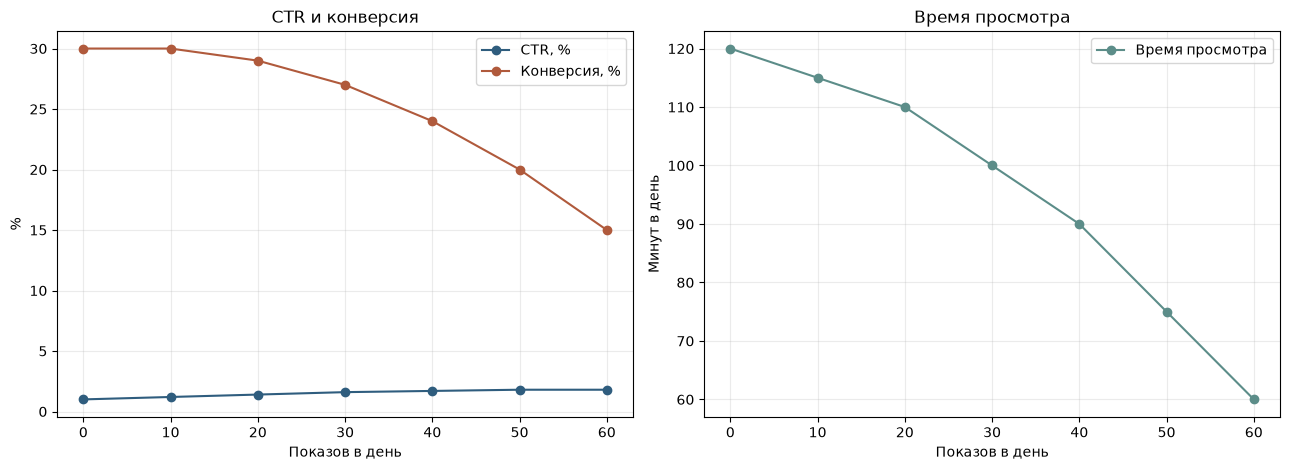

In [12]:
if cohort_cfg['enabled']:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    axes[0].plot(cohort['Нагрузка, показов/день'], cohort['CTR, %'], marker='o', label='CTR, %', color='#2F5D7E')
    axes[0].plot(cohort['Нагрузка, показов/день'], cohort['Конверсия в подписку, %'], marker='o', label='Конверсия, %', color='#B05A3C')
    axes[0].set_title('CTR и конверсия'); axes[0].set_xlabel('Показов в день'); axes[0].set_ylabel('%'); axes[0].grid(alpha=.25); axes[0].legend()
    axes[1].plot(cohort['Нагрузка, показов/день'], cohort['Время просмотра, мин'], marker='o', label='Время просмотра', color='#5C8D89')
    axes[1].set_title('Время просмотра'); axes[1].set_xlabel('Показов в день'); axes[1].set_ylabel('Минут в день'); axes[1].grid(alpha=.25); axes[1].legend()
    fig.tight_layout(); fig.savefig(ROOT/'reports'/'figures'/'task_04_cohort_metrics.png', dpi=180, bbox_inches='tight'); plt.show()

In [13]:
%%capture
!python -m jupyter nbconvert --to html --no-input --output-dir ../reports --output task_04_report task_04_ad_load.ipynb